In [27]:
!pip -q install kagglehub transformers

In [28]:
import os
import re
import time
import random
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [29]:
import kagglehub
from pathlib import Path

dataset_path = kagglehub.dataset_download(
    "ashfakyeafi/spam-email-classification"
)

print("Dataset location:", dataset_path)

csv_files = list(Path(dataset_path).rglob("*.csv"))

print("CSV files found:")
for i, file in enumerate(csv_files):
    print(i, file)

if not csv_files:
    raise FileNotFoundError(
        "No CSV found. Download the dataset from Kaggle "
        "and upload its CSV file to Colab."
    )
DATA_FILE_INDEX = 0
df_raw = pd.read_csv(
    csv_files[DATA_FILE_INDEX],
    encoding_errors="replace",
    low_memory=False
)

print("Dataset shape:", df_raw.shape)
display(df_raw.head())
print("Columns:", df_raw.columns.tolist())

Using Colab cache for faster access to the 'spam-email-classification' dataset.
Dataset location: /kaggle/input/spam-email-classification
CSV files found:
0 /kaggle/input/spam-email-classification/email.csv
Dataset shape: (5573, 2)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Columns: ['Category', 'Message']


In [30]:
print("Dataset shape:", df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nMissing values:")
display(df_raw.isnull().sum().to_frame("Missing values"))

print("\nDuplicate rows:", df_raw.duplicated().sum())

print("\nUnique values per column:")
display(df_raw.nunique().to_frame("Unique values"))

print("\nSample records:")
display(df_raw.head(10))

for col in df_raw.columns:
    print(f"\nColumn: {col}")
    print(df_raw[col].dropna().astype(str).head(3).tolist())

Dataset shape: (5573, 2)

Column names:
['Category', 'Message']

Missing values:


,Missing values
Category,0
Message,0



Duplicate rows: 415

Unique values per column:


,Unique values
Category,3
Message,5158



Sample records:


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...



Column: Category
['ham', 'ham', 'spam']

Column: Message
['Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...', 'Ok lar... Joking wif u oni...', "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"]


In [31]:
def normalize_column_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

column_map = {
    normalize_column_name(col): col
    for col in df_raw.columns
}

text_candidates = [
    "text", "emailtext", "email", "message",
    "body", "content", "v2"
]

label_candidates = [
    "label", "category", "type", "class",
    "target", "spam", "v1"
]

TEXT_COL = next(
    (column_map[c] for c in text_candidates if c in column_map),
    None
)

LABEL_COL = next(
    (column_map[c] for c in label_candidates if c in column_map),
    None
)

print("Detected text column:", TEXT_COL)
print("Detected label column:", LABEL_COL)

Detected text column: Message
Detected label column: Category



Original class counts:


,Count
Category,
ham,4825
spam,747
"{""mode"":""full""",1


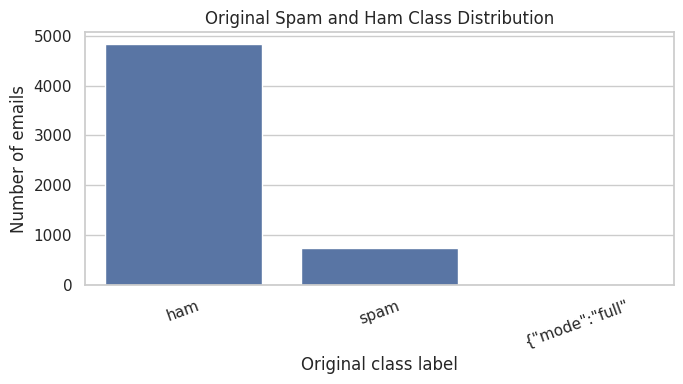

In [32]:
if TEXT_COL is None or LABEL_COL is None or TEXT_COL == LABEL_COL:
    raise ValueError(
        "Set TEXT_COL and LABEL_COL manually using the actual column names."
    )

print("\nOriginal class counts:")
display(df_raw[LABEL_COL].value_counts(dropna=False).to_frame("Count"))

plt.figure(figsize=(7, 4))
sns.countplot(
    x=df_raw[LABEL_COL].astype(str),
    order=df_raw[LABEL_COL].astype(str).value_counts().index
)
plt.title("Original Spam and Ham Class Distribution")
plt.xlabel("Original class label")
plt.ylabel("Number of emails")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Rows before cleaning: 5573
Rows after removing missing/empty/corrupt data: 5572
Rows after duplicate removal: 5157

Cleaned class distribution:


,Count
class_name,
Ham,4516
Spam,641


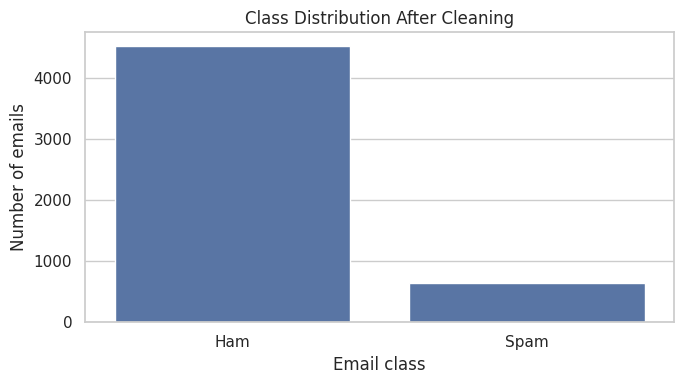

In [33]:
def convert_label(value):
    if pd.isna(value):
        return np.nan

    label = str(value).strip().lower()

    if label in {"ham", "not spam", "non-spam", "nonspam",
                 "legitimate", "normal", "0", "false", "no"}:
        return 0

    if label in {"spam", "junk", "1", "true", "yes", "phishing"}:
        return 1

    if "not spam" in label or "non-spam" in label or "nonspam" in label:
        return 0

    if "spam" in label or "phishing" in label or "junk" in label:
        return 1

    return np.nan


data = df_raw[[TEXT_COL, LABEL_COL]].copy()
data.columns = ["text", "original_label"]

rows_before = len(data)

data = data[
    ~data["original_label"].astype(str).str.contains(r"\{|\}", na=False)
].copy()

data = data.dropna(subset=["text", "original_label"]).copy()
data["text"] = data["text"].astype(str).str.strip()
data = data[data["text"] != ""].copy()

data["label"] = data["original_label"].apply(convert_label)

if data["label"].isna().any():
    print("Unrecognized labels:")
    display(
        data.loc[data["label"].isna(), "original_label"]
        .value_counts()
        .to_frame("Count")
    )
    raise ValueError(
        "Update convert_label() to match the actual dataset labels."
    )

data["label"] = data["label"].astype(int)

print("Rows before cleaning:", rows_before)
print("Rows after removing missing/empty/corrupt data:", len(data))

data = data.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Rows after duplicate removal:", len(data))

assert set(data["label"].unique()) == {0, 1}, (
    "Expected two classes: 0=Ham and 1=Spam. "
    "Check the label mapping."
)

data["class_name"] = data["label"].map({
    0: "Ham",
    1: "Spam"
})

print("\nCleaned class distribution:")
display(data["class_name"].value_counts().to_frame("Count"))

plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="class_name", order=["Ham", "Spam"])
plt.title("Class Distribution After Cleaning")
plt.xlabel("Email class")
plt.ylabel("Number of emails")
plt.tight_layout()
plt.show()

In [34]:
X = data["text"].astype(str).to_numpy()
y = data["label"].astype(int).to_numpy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Samples": [len(y_train), len(y_val), len(y_test)],
    "Ham": [
        int((y_train == 0).sum()),
        int((y_val == 0).sum()),
        int((y_test == 0).sum())
    ],
    "Spam": [
        int((y_train == 1).sum()),
        int((y_val == 1).sum()),
        int((y_test == 1).sum())
    ]
})

display(split_summary)

Training samples: 3609
Validation samples: 774
Testing samples: 774


,Split,Samples,Ham,Spam
0,Train,3609,3160,449
1,Validation,774,678,96
2,Test,774,678,96


In [35]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text


tfidf_settings = {
    "preprocessor": clean_text,
    "ngram_range": (1, 2),
    "max_features": 50000,
    "sublinear_tf": True,
    "strip_accents": "unicode",
    "dtype": np.float32
}

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_settings)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=SEED
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_settings)),
        ("classifier", MultinomialNB(alpha=1.0))
    ])
}

traditional_times = {}
predictions = {}
results = []

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        )
    }


for model_name, model in models.items():

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    elapsed = time.perf_counter() - start_time
    traditional_times[model_name] = elapsed

    val_pred = model.predict(X_val)

    print(f"\n{model_name}")
    print("Training time:", round(elapsed, 2), "seconds")

    print(
        classification_report(
            y_val,
            val_pred,
            labels=[0, 1],
            target_names=["Ham", "Spam"],
            zero_division=0
        )
    )


    test_pred = model.predict(X_test)
    predictions[model_name] = test_pred

    row = {
        "Model": model_name,
        **calculate_metrics(y_test, test_pred),
        "Training time (seconds)": elapsed
    }

    results.append(row)

traditional_results = pd.DataFrame(results)
display(traditional_results.round(4))


Logistic Regression
Training time: 0.79 seconds
              precision    recall  f1-score   support

         Ham       0.95      1.00      0.97       678
        Spam       1.00      0.61      0.76        96

    accuracy                           0.95       774
   macro avg       0.97      0.81      0.87       774
weighted avg       0.95      0.95      0.95       774


Naive Bayes
Training time: 0.19 seconds
              precision    recall  f1-score   support

         Ham       0.93      1.00      0.96       678
        Spam       1.00      0.48      0.65        96

    accuracy                           0.94       774
   macro avg       0.97      0.74      0.81       774
weighted avg       0.94      0.94      0.93       774



,Model,Accuracy,Precision,Recall,F1-score,Training time (seconds)
0,Logistic Regression,0.9612,1.0,0.6875,0.8148,0.7923
1,Naive Bayes,0.9393,1.0,0.5104,0.6759,0.1865


In [36]:
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

MODEL_NAME = "distilbert-base-uncased"

MAX_LENGTH = 256
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully.")
print("Training device:", DEVICE)

Tokenizer loaded successfully.
Training device: cuda


In [37]:
class SpamDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=256):
        self.texts = list(texts)
        self.labels = list(map(int, labels))
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = str(self.texts[index])
        label = self.labels[index]

        encoded = self.tokenizer(
            text,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }


train_dataset = SpamDataset(
    X_train, y_train, tokenizer, MAX_LENGTH
)

val_dataset = SpamDataset(
    X_val, y_val, tokenizer, MAX_LENGTH
)

test_dataset = SpamDataset(
    X_test, y_test, tokenizer, MAX_LENGTH
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 226
Validation batches: 49
Testing batches: 49


In [38]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "Ham", 1: "Spam"},
    label2id={"Ham": 0, "Spam": 1}
)

model = model.to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(0.1 * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("Model loaded.")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded.
Trainable parameters: 66955010


In [39]:
def evaluate_model(model, loader):

    model.eval()

    total_loss = 0
    total_samples = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for batch in loader:

            batch = {
                key: value.to(DEVICE)
                for key, value in batch.items()
            }

            outputs = model(**batch)

            batch_size = batch["labels"].size(0)

            total_loss += outputs.loss.item() * batch_size
            total_samples += batch_size

            predicted = torch.argmax(outputs.logits, dim=1)

            all_predictions.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                batch["labels"].cpu().numpy()
            )

    avg_loss = total_loss / max(total_samples, 1)

    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)

    metrics = calculate_metrics(all_labels, all_predictions)

    return avg_loss, metrics, all_labels, all_predictions

In [40]:

import time
import copy
import torch
import pandas as pd
from torch.amp import autocast, GradScaler

EPOCHS = 2
MAX_LENGTH = 128

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(DEVICE)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU. Training may be slow.")

use_amp = DEVICE.type == "cuda"
scaler = GradScaler("cuda", enabled=use_amp)

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": [],
    "epoch_time": []
}

best_val_f1 = -1
best_state = None

transformer_start = time.perf_counter()

for epoch in range(EPOCHS):
    epoch_start = time.perf_counter()
    model.train()

    total_train_loss = 0.0
    total_train_samples = 0

    for step, batch in enumerate(train_loader):
        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        with autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        batch_size = batch["labels"].size(0)
        total_train_loss += loss.item() * batch_size
        total_train_samples += batch_size

        if (step + 1) % 20 == 0 or (step + 1) == len(train_loader):
            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Batch {step + 1}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    train_loss = total_train_loss / max(total_train_samples, 1)

    val_loss, val_metrics, _, _ = evaluate_model(
        model, val_loader
    )

    epoch_time = time.perf_counter() - epoch_start

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_metrics["Accuracy"])
    history["val_precision"].append(val_metrics["Precision"])
    history["val_recall"].append(val_metrics["Recall"])
    history["val_f1"].append(val_metrics["F1-score"])
    history["epoch_time"].append(epoch_time)

    print(f"\nEpoch {epoch + 1} completed")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation accuracy: {val_metrics['Accuracy']:.4f}")
    print(f"Validation F1: {val_metrics['F1-score']:.4f}")
    print(f"Epoch time: {epoch_time:.2f} seconds")

    if val_metrics["F1-score"] > best_val_f1:
        best_val_f1 = val_metrics["F1-score"]
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_state,
            "/content/best_distilbert_spam.pt"
        )
        print("Best model checkpoint saved.")

    print("-" * 50)

transformer_training_time = (
    time.perf_counter() - transformer_start
)

if best_state is not None:
    model.load_state_dict(best_state)

print(
    "DistilBERT training time:",
    round(transformer_training_time, 2),
    "seconds"
)
print("Best validation F1:", round(best_val_f1, 4))

history_df = pd.DataFrame(history)
display(history_df)

Device: cuda
GPU: Tesla T4
Epoch 1/2 | Batch 20/226 | Loss: 0.5865
Epoch 1/2 | Batch 40/226 | Loss: 0.3659
Epoch 1/2 | Batch 60/226 | Loss: 0.0337
Epoch 1/2 | Batch 80/226 | Loss: 0.2889
Epoch 1/2 | Batch 100/226 | Loss: 0.0120
Epoch 1/2 | Batch 120/226 | Loss: 0.0487
Epoch 1/2 | Batch 140/226 | Loss: 0.0064
Epoch 1/2 | Batch 160/226 | Loss: 0.0089
Epoch 1/2 | Batch 180/226 | Loss: 0.0040
Epoch 1/2 | Batch 200/226 | Loss: 0.2061
Epoch 1/2 | Batch 220/226 | Loss: 0.0053
Epoch 1/2 | Batch 226/226 | Loss: 0.0054

Epoch 1 completed
Training loss: 0.1626
Validation loss: 0.0555
Validation accuracy: 0.9858
Validation F1: 0.9399
Epoch time: 37.89 seconds
Best model checkpoint saved.
--------------------------------------------------
Epoch 2/2 | Batch 20/226 | Loss: 0.0246
Epoch 2/2 | Batch 40/226 | Loss: 0.0057
Epoch 2/2 | Batch 60/226 | Loss: 0.0027
Epoch 2/2 | Batch 80/226 | Loss: 0.0039
Epoch 2/2 | Batch 100/226 | Loss: 0.0026
Epoch 2/2 | Batch 120/226 | Loss: 0.3709
Epoch 2/2 | Batch 140/

,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,epoch_time
0,1,0.162564,0.055460,0.985788,0.988506,0.895833,0.939891,37.886427
1,2,0.021045,0.072407,0.984496,0.977273,0.895833,0.934783,35.301532


,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,epoch_time
0,1,0.1626,0.0555,0.9858,0.9885,0.8958,0.9399,37.8864
1,2,0.0210,0.0724,0.9845,0.9773,0.8958,0.9348,35.3015


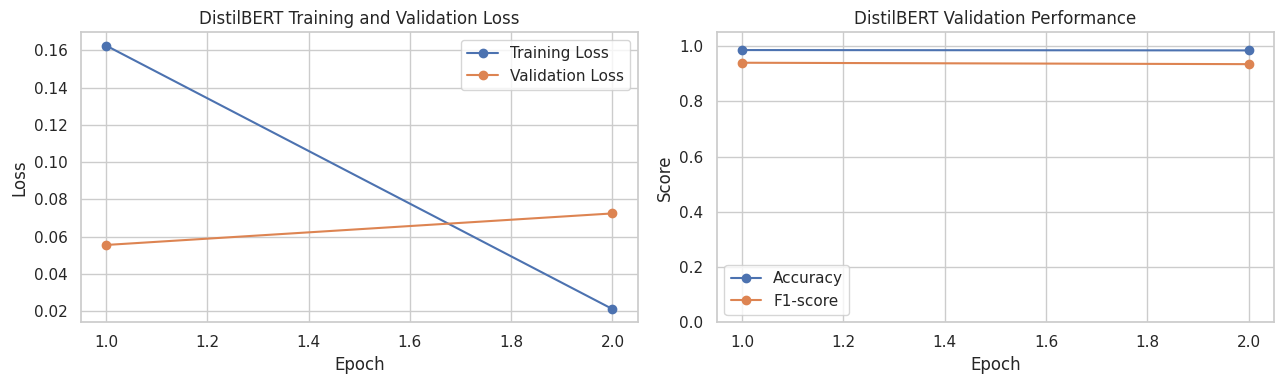

In [41]:
history_df = pd.DataFrame(history)

display(history_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("DistilBERT Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_f1"],
    marker="o",
    label="F1-score"
)

axes[1].set_title("DistilBERT Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1.05)
axes[1].legend()

plt.tight_layout()
plt.show()

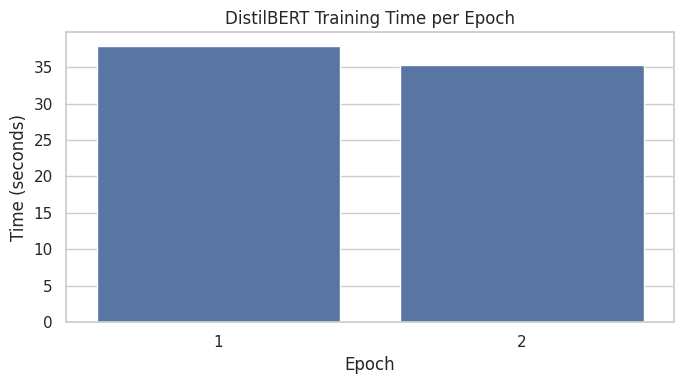

In [42]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=history_df,
    x="epoch",
    y="epoch_time"
)

plt.title("DistilBERT Training Time per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Time (seconds)")

plt.tight_layout()
plt.show()

In [43]:
if best_state is None:
    raise RuntimeError("Training did not produce a model checkpoint.")

model.load_state_dict(best_state)
model.eval()

test_loss, bert_metrics, bert_true, bert_pred = evaluate_model(
    model,
    test_loader
)

predictions["DistilBERT"] = bert_pred

results.append({
    "Model": "DistilBERT",
    **bert_metrics,
    "Training time (seconds)": transformer_training_time
})

print("DistilBERT test loss:", round(test_loss, 4))

print("\nDistilBERT Test Classification Report:")

print(
    classification_report(
        bert_true,
        bert_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

DistilBERT test loss: 0.0431

DistilBERT Test Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       678
        Spam       0.98      0.92      0.95        96

    accuracy                           0.99       774
   macro avg       0.98      0.96      0.97       774
weighted avg       0.99      0.99      0.99       774



In [44]:
results_df = pd.DataFrame(results)

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

print("Final test-set results:")

display(
    results_df[
        ["Model"] + metric_columns + ["Training time (seconds)"]
    ].round(4)
)

Final test-set results:


,Model,Accuracy,Precision,Recall,F1-score,Training time (seconds)
0,Logistic Regression,0.9612,1.0000,0.6875,0.8148,0.7923
1,Naive Bayes,0.9393,1.0000,0.5104,0.6759,0.1865
2,DistilBERT,0.9871,0.9778,0.9167,0.9462,74.9325


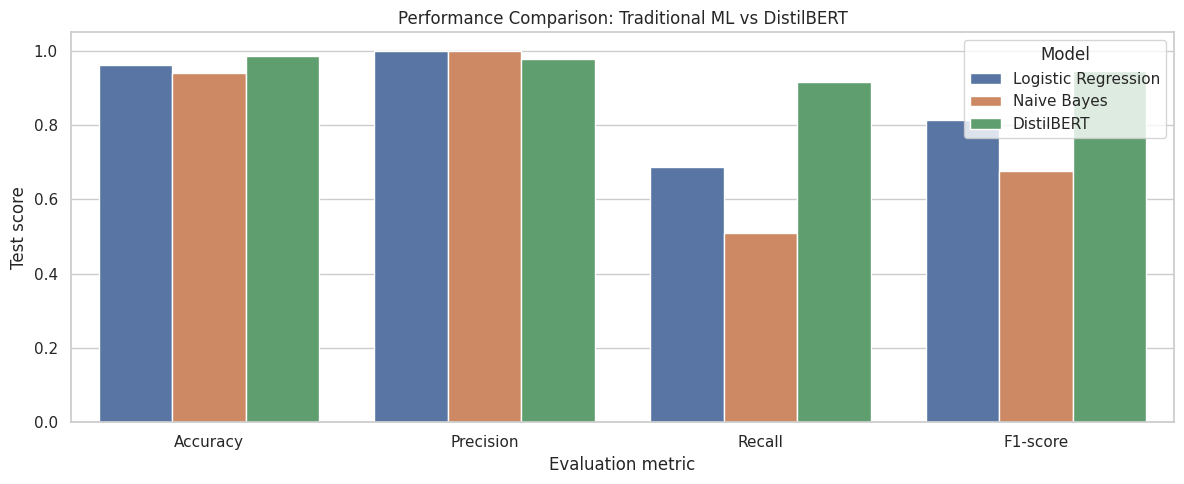

In [45]:
metrics_long = results_df.melt(
    id_vars="Model",
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=metrics_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Performance Comparison: Traditional ML vs DistilBERT")
plt.xlabel("Evaluation metric")
plt.ylabel("Test score")
plt.ylim(0, 1.05)
plt.legend(title="Model")

plt.tight_layout()
plt.show()

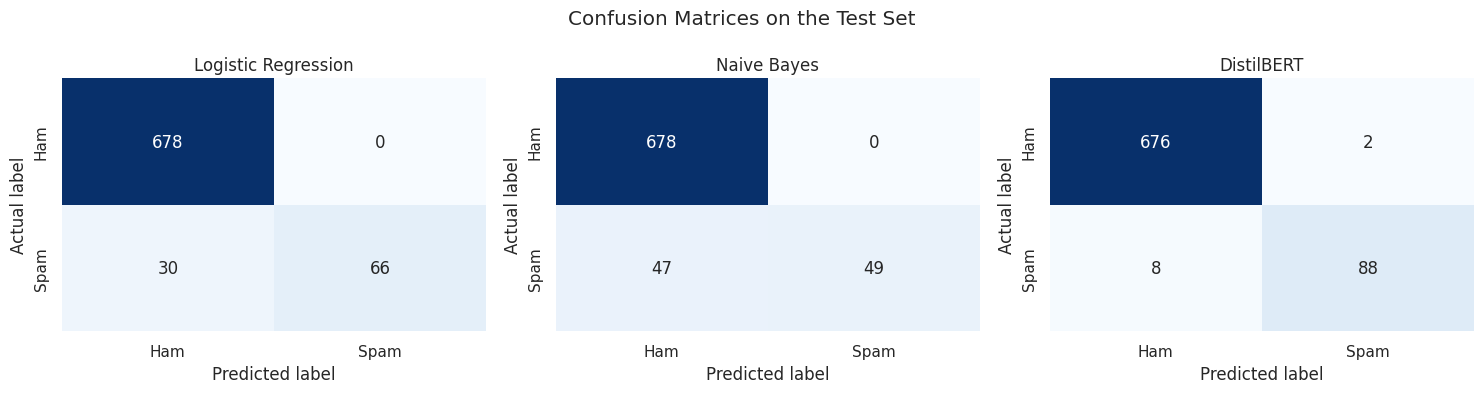

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.suptitle("Confusion Matrices on the Test Set")
plt.tight_layout()
plt.show()

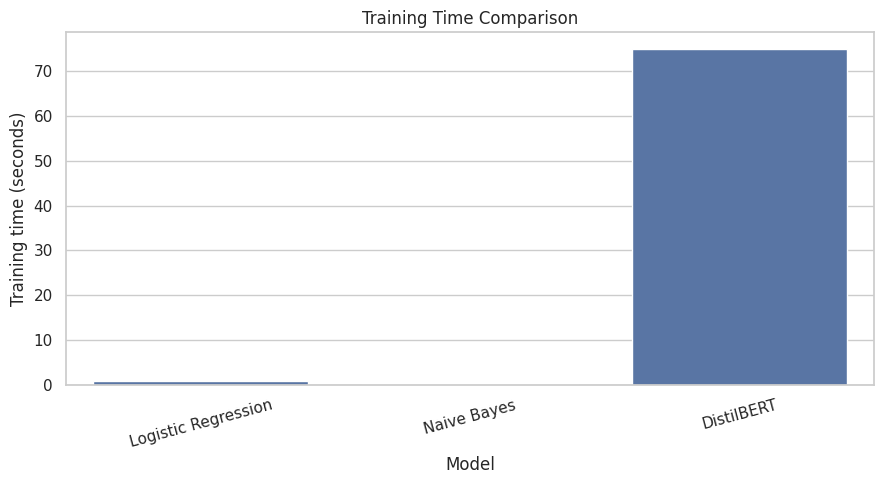

Hardware used: cuda


In [47]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Training time (seconds)"
)

plt.title("Training Time Comparison")
plt.xlabel("Model")
plt.ylabel("Training time (seconds)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

print("Hardware used:", DEVICE)

In [48]:
print("Classification Results:")
print(results_df.to_string(index=False))

print("\nTraining History:")
print(history_df.to_string(index=False))

print("\nDataset Split Summary:")
print(split_summary.to_string(index=False))

Classification Results:
              Model  Accuracy  Precision   Recall  F1-score  Training time (seconds)
Logistic Regression  0.961240   1.000000 0.687500  0.814815                 0.792305
        Naive Bayes  0.939276   1.000000 0.510417  0.675862                 0.186477
         DistilBERT  0.987080   0.977778 0.916667  0.946237                74.932468

Training History:
 epoch  train_loss  val_loss  val_accuracy  val_precision  val_recall   val_f1  epoch_time
     1    0.162564  0.055460      0.985788       0.988506    0.895833 0.939891   37.886427
     2    0.021045  0.072407      0.984496       0.977273    0.895833 0.934783   35.301532

Dataset Split Summary:
     Split  Samples  Ham  Spam
     Train     3609 3160   449
Validation      774  678    96
      Test      774  678    96


In [49]:
best_model = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("Best model based on test F1-score:")
print(best_model["Model"])

print("\nAccuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-score:", round(best_model["F1-score"], 4))

print("\nFastest model by measured training time:")

fastest_model = results_df.loc[
    results_df["Training time (seconds)"].idxmin()
]

print(fastest_model["Model"])
print(
    "Training time:",
    round(fastest_model["Training time (seconds)"], 2),
    "seconds"
)

Best model based on test F1-score:
DistilBERT

Accuracy: 0.9871
Precision: 0.9778
Recall: 0.9167
F1-score: 0.9462

Fastest model by measured training time:
Naive Bayes
Training time: 0.19 seconds
